# Model Evaluation

This notebook evaluates the models trained in the modeling notebook on the held-out test set.

The evaluation uses the metrics defined in the business understanding notebook:

- **MAE** (primary metric), **MSE**, and **RMSE**
- **R²**, as a complementary measure of explained variance
- **Relative error**, to compare the results with the preliminary 10–15% target

The Dummy model (training mean) and Linear Regression serve as reference points for the selected model.

## 1. Load Test Data and Predictions

In [6]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

artifacts_dir = "../artifacts"

y_test = np.asarray(joblib.load(os.path.join(artifacts_dir, "y_test.joblib")))
test_predictions = joblib.load(os.path.join(artifacts_dir, "test_predictions.joblib"))
best_model_name = joblib.load(os.path.join(artifacts_dir, "best_model_name.joblib"))

print("Selected model:", best_model_name)
print("Models evaluated:", list(test_predictions.keys()))
print("Test set size:", len(y_test))

Selected model: Hist Gradient Boosting
Models evaluated: ['Dummy (mean)', 'Linear Regression', 'Random Forest', 'Hist Gradient Boosting']
Test set size: 4128


## 2. Calculate Evaluation Metrics

For every model, the following metrics are computed on the test set:

- **MAE:** average absolute prediction error, in dollars.
- **MSE:** average squared error, which penalizes large errors heavily (in dollars squared).
- **RMSE:** square root of MSE, in dollars.
- **R² Score:** share of target variance explained compared with predicting the mean.
- **Relative MAE:** MAE divided by the mean of the actual test values.
- **Median APE:** median absolute percentage error per district, which is less affected by a few extreme errors than the mean.

In [7]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluate(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    ape = np.abs(y_true - y_pred) / y_true
    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R²": r2_score(y_true, y_pred),
        "Relative MAE (%)": 100 * mae / y_true.mean(),
        "Median APE (%)": 100 * np.median(ape),
    }

results = pd.DataFrame(
    {name: evaluate(y_test, pred) for name, pred in test_predictions.items()}
).T

results.round(4)

,MAE,MSE,RMSE,R²,Relative MAE (%),Median APE (%)
Dummy (mean),90606.8549,1.310696e+10,114485.6354,-0.0002,44.0909,38.9851
Linear Regression,49645.4924,4.778547e+09,69127.0383,0.6353,24.1584,20.9673
Random Forest,31926.2697,2.483401e+09,49833.7324,0.8105,15.5359,11.6406
Hist Gradient Boosting,30474.2193,2.138284e+09,46241.5845,0.8368,14.8293,11.6807


In [8]:
summary = results[["MAE", "RMSE", "R²", "Relative MAE (%)", "Median APE (%)"]].copy()
summary["MAE"] = summary["MAE"].map("${:,.0f}".format)
summary["RMSE"] = summary["RMSE"].map("${:,.0f}".format)
summary["R²"] = summary["R²"].round(4)
summary["Relative MAE (%)"] = summary["Relative MAE (%)"].round(1)
summary["Median APE (%)"] = summary["Median APE (%)"].round(1)
summary

,MAE,RMSE,R²,Relative MAE (%),Median APE (%)
Dummy (mean),"$90,607","$114,486",-0.0002,44.1,39.0
Linear Regression,"$49,645","$69,127",0.6353,24.2,21.0
Random Forest,"$31,926","$49,834",0.8105,15.5,11.6
Hist Gradient Boosting,"$30,474","$46,242",0.8368,14.8,11.7


### Observations

- The Linear Regression results (MAE $49,645, RMSE $69,127, R² 0.6353) match the baseline reported in the earlier version of this notebook, so the pipeline is reproducible.
- The test results are consistent with the cross-validation results, which suggests the model selection did not overfit to the training data.
- The selected model, Histogram Gradient Boosting, reaches an MAE of about $30,600, an RMSE of about $46,300, and an R² of about 0.84. Compared with Linear Regression, the MAE is about 38% lower.
- RMSE is clearly higher than MAE for every model, which means a minority of districts have large errors.
- Random Forest is close behind (MAE ≈ $31,900) and has a slightly lower median APE (11.6% vs 11.9%), so the two tree-based models are close in practice (their difference is examined in Section 5). Gradient Boosting is preferred because it has the better cross-validated and test MAE and RMSE.
- The Dummy model is far behind (relative MAE ≈ 44%), so all other models add real predictive value.

## 3. Effect of the Capped Target Values

The target variable is capped at 500,001, so for those districts the recorded value is not the true value. To see how much this affects the results, the selected model is evaluated on all test records and on the records that are **not** capped.

In [9]:
best_pred = np.asarray(test_predictions[best_model_name])
not_capped = y_test < 500001

print("Capped records in test set:", int((~not_capped).sum()),
      f"({100 * (~not_capped).mean():.1f}%)")

cap_comparison = pd.DataFrame({
    "All test records": evaluate(y_test, best_pred),
    "Excluding capped records": evaluate(y_test[not_capped], best_pred[not_capped]),
}).T

cap_comparison.round(4)

Capped records in test set: 179 (4.3%)


,MAE,MSE,RMSE,R²,Relative MAE (%),Median APE (%)
All test records,30474.2193,2.138284e+09,46241.5845,0.8368,14.8293,11.6807
Excluding capped records,28938.8102,1.807313e+09,42512.5015,0.8115,15.0604,11.8582


### Observations

- 179 test records (about 4.3%) have the capped target value of 500,001.
- Excluding them lowers the absolute errors (MAE ≈ $29,000, RMSE ≈ $42,400), but the relative MAE stays almost the same (about 15%), and R² is lower (0.81 vs 0.84). R² is lower because removing the capped records also reduces the variance of the target.
- The cap therefore does not change the overall conclusion. However, because the true values of the capped districts are unknown, results for the most expensive districts should be interpreted with caution.

## 4. Predicted vs Actual Values

The plot compares the selected model's predictions with the actual values. Points on the dashed line are perfect predictions. The vertical band of points at the right edge (actual value = 500,001) corresponds to the capped target values, whose true values are unknown.

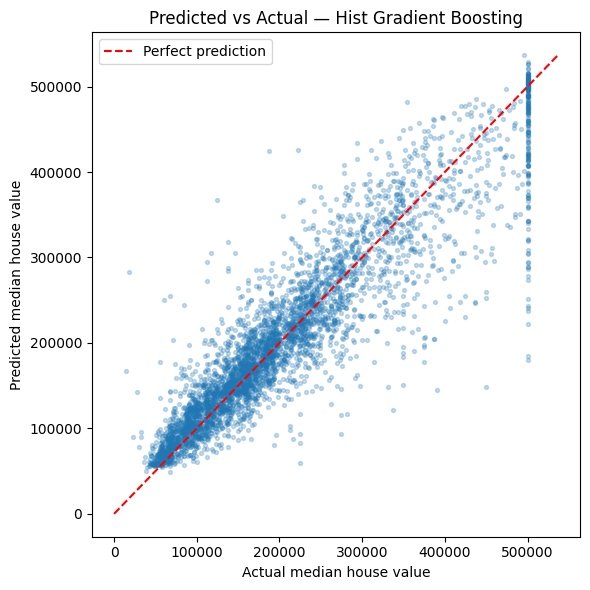

In [10]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, best_pred, alpha=0.25, s=8)
limits = [0, max(y_test.max(), best_pred.max())]
ax.plot(limits, limits, "r--", label="Perfect prediction")
ax.set_xlabel("Actual median house value")
ax.set_ylabel("Predicted median house value")
ax.set_title(f"Predicted vs Actual — {best_model_name}")
ax.legend()
plt.tight_layout()
plt.show()

### Error by Predicted-Value Range

The plot suggests that the error is not the same across the price range. To check this without selecting records by their actual value (which would distort the picture), the test records are grouped into five equal-sized groups by the **predicted** value, and the average actual value and the errors are compared in each group.

In [11]:
pred_group = pd.qcut(best_pred, 5, labels=["lowest", "low", "middle", "high", "highest"])

by_pred = pd.DataFrame({"actual": y_test, "predicted": best_pred, "group": pred_group})
by_pred["abs_error"] = (by_pred["actual"] - by_pred["predicted"]).abs()
by_pred["signed_error"] = by_pred["predicted"] - by_pred["actual"]

group_summary = by_pred.groupby("group", observed=True).agg(
    districts=("actual", "size"),
    mean_predicted=("predicted", "mean"),
    mean_actual=("actual", "mean"),
    mean_signed_error=("signed_error", "mean"),
    MAE=("abs_error", "mean"),
)
group_summary["relative_MAE_%"] = 100 * group_summary["MAE"] / group_summary["mean_actual"]
group_summary.round(0)

,districts,mean_predicted,mean_actual,mean_signed_error,MAE,relative_MAE_%
group,,,,,,
lowest,826,87733.0,86822.0,912.0,16502.0,19.0
low,825,138697.0,138917.0,-221.0,23841.0,17.0
middle,826,184710.0,183346.0,1364.0,28009.0,15.0
high,825,242177.0,241506.0,671.0,37081.0,15.0
highest,826,376369.0,376873.0,-504.0,46938.0,12.0


#### Observations

* On average, the model is well calibrated across the five groups: the mean predicted value is within about $1,200 of the mean actual value in every group.
* The absolute error grows with the price level (MAE of about $16,100 in the lowest group and $47,100 in the highest), but the relative error falls (from about 19% to about 12%). The cheaper districts therefore have the largest relative errors.
* The scatter plot may give the impression that expensive districts are systematically under-predicted. Grouping by the predicted value does not show this. Grouping by the actual value would produce that pattern even for a well-calibrated model, which is why it is not used here.
* Capped districts (4.3% of the test set) have unknown true values, so the error figures for them are not exact.

## 5. Uncertainty of the Test Estimates

All the numbers above come from a single test set of 4,128 districts, so they are estimates and would change somewhat with a different sample. To see how much, the test set is resampled with replacement 1,000 times (bootstrap), and the MAE is recalculated each time. The same resamples are used for the models, so the difference between two models can be compared directly.

In [12]:
rng = np.random.default_rng(42)
n = len(y_test)
n_boot = 1000

pred_hgb = np.asarray(test_predictions["Hist Gradient Boosting"])
pred_rf = np.asarray(test_predictions["Random Forest"])

abs_err_hgb = np.abs(y_test - pred_hgb)
abs_err_rf = np.abs(y_test - pred_rf)

mae_hgb, mae_rf, rel_hgb = [], [], []
for _ in range(n_boot):
    idx = rng.integers(0, n, n)
    mae_hgb.append(abs_err_hgb[idx].mean())
    mae_rf.append(abs_err_rf[idx].mean())
    rel_hgb.append(abs_err_hgb[idx].mean() / y_test[idx].mean() * 100)

mae_hgb, mae_rf, rel_hgb = map(np.array, (mae_hgb, mae_rf, rel_hgb))
diff = mae_rf - mae_hgb

def ci(a):
    return np.percentile(a, [2.5, 97.5])

print("Hist Gradient Boosting MAE, 95% interval: ", ci(mae_hgb).round(0))
print("Random Forest MAE, 95% interval:          ", ci(mae_rf).round(0))
print("MAE difference (RF - HGB), 95% interval:  ", ci(diff).round(0))
print("HGB relative MAE (%), 95% interval:       ", ci(rel_hgb).round(2))
print("Share of resamples where HGB beats RF:    ", (diff > 0).mean())

Hist Gradient Boosting MAE, 95% interval:  [29325. 31589.]
Random Forest MAE, 95% interval:           [30719. 33116.]
MAE difference (RF - HGB), 95% interval:   [ 949. 2050.]
HGB relative MAE (%), 95% interval:        [14.32 15.33]
Share of resamples where HGB beats RF:     1.0


#### Observations

* The 95% bootstrap interval for the selected model's MAE is about $29,500 to $31,700, and for its relative MAE about 14.4% to 15.4%. The upper end is above the 15% target, so the evidence that the model meets the target is not conclusive.
* Hist Gradient Boosting has a lower MAE than Random Forest in all 1,000 resamples (difference of about $860 to $1,900). The gap is small but consistent on this test set.
* This bootstrap only captures the variation due to which districts are in the test set. It does not include the variation from retraining the models on different training data or with different random seeds.

## 6. Comparison with the Success Criteria

The business understanding notebook set a preliminary relative-error target of about 10–15%, provided the calculation method is explicitly defined. Here, the target is checked with two explicitly defined measures: relative MAE (MAE divided by the mean actual value) and median absolute percentage error.

In [13]:
target_upper = 15

for name in results.index:
    rel = results.loc[name, "Relative MAE (%)"]
    med = results.loc[name, "Median APE (%)"]
    print(f"{name:25s} relative MAE = {rel:5.1f}%   median APE = {med:5.1f}%")

print()
print("Selected model relative MAE:",
      f"{results.loc[best_model_name, 'Relative MAE (%)']:.1f}%",
      "| meets 15% target:",
      bool(results.loc[best_model_name, "Relative MAE (%)"] <= target_upper))

Dummy (mean)              relative MAE =  44.1%   median APE =  39.0%
Linear Regression         relative MAE =  24.2%   median APE =  21.0%
Random Forest             relative MAE =  15.5%   median APE =  11.6%
Hist Gradient Boosting    relative MAE =  14.8%   median APE =  11.7%

Selected model relative MAE: 14.8% | meets 15% target: True


### Conclusion

- The selected model, **Histogram Gradient Boosting**, clearly outperforms both the Dummy baseline and Linear Regression on the held-out test set (MAE ≈ $30,600, RMSE ≈ $46,300, R² ≈ 0.84).
- Its relative MAE is about 14.9% (95% bootstrap interval: 14.4% to 15.4%), at the upper end of the preliminary 10–15% target, and its median APE is about 11.9%. Because the interval crosses 15%, the result should be described as close to the target rather than as clearly meeting it. The target was also defined as approximate.
- These results come from default hyperparameters and a single train/test split on 1990 district-level data. They describe the quality of the methodology on this dataset, not accuracy on current housing prices.
- Possible next steps are hyperparameter tuning, feature importance analysis, and checking whether the engineered ratio features improve the tree-based models.